# Дополнительное задание к ЛР №3 — глубокая кластеризация погодных наблюдений

**Метод:** автокодировщик (Autoencoder) + K-means.  
**Цель:** проверить, помогает ли нелинейное латентное представление выделять погодные режимы лучше классических методов.

Столбец `RainTomorrow` не используется при обучении и подборе кластеров. Он применяется только после обучения для внешней диагностической оценки.

## 1. Загрузка и первичный анализ данных

Используется тот же набор *Rain in Australia* с Kaggle. Он содержит ежедневные метеорологические наблюдения; признаки включают температуру, влажность, давление, облачность, скорость и направление ветра.

In [68]:
!pip -q install kagglehub[pandas-datasets]

In [69]:
import os
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '2'

import warnings
warnings.filterwarnings('ignore')
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
import kagglehub
from kagglehub import KaggleDatasetAdapter

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.cluster import KMeans
from sklearn.mixture import GaussianMixture
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.metrics import (silhouette_score, davies_bouldin_score, calinski_harabasz_score,
                             adjusted_rand_score, normalized_mutual_info_score,
                             homogeneity_completeness_v_measure)
from tensorflow.keras import layers, regularizers, Model
from IPython.display import display

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
tf.keras.utils.set_random_seed(RANDOM_STATE)
sns.set_theme(style='whitegrid', palette='deep')
pd.set_option('display.max_columns', 100)

In [70]:
df = kagglehub.load_dataset(
    KaggleDatasetAdapter.PANDAS,
    'jsphyg/weather-dataset-rattle-package',
    'weatherAUS.csv'
)
display(df.head())

overview = pd.DataFrame({
    'Тип данных': df.dtypes.astype(str),
    'Пропусков': df.isna().sum(),
    'Пропусков, %': (df.isna().mean() * 100).round(2),
    'Уникальных значений': df.nunique()
}).sort_values('Пропусков, %', ascending=False)
display(overview)

Using Colab cache for faster access to the 'weather-dataset-rattle-package' dataset.


,Date,Location,MinTemp,MaxTemp,Rainfall,Evaporation,Sunshine,WindGustDir,WindGustSpeed,WindDir9am,WindDir3pm,WindSpeed9am,WindSpeed3pm,Humidity9am,Humidity3pm,Pressure9am,Pressure3pm,Cloud9am,Cloud3pm,Temp9am,Temp3pm,RainToday,RainTomorrow
0,2008-12-01,Albury,13.4,22.9,0.6,NaN,NaN,W,44.0,W,WNW,20.0,24.0,71.0,22.0,1007.7,1007.1,8.0,NaN,16.9,21.8,No,No
1,2008-12-02,Albury,7.4,25.1,0.0,NaN,NaN,WNW,44.0,NNW,WSW,4.0,22.0,44.0,25.0,1010.6,1007.8,NaN,NaN,17.2,24.3,No,No
2,2008-12-03,Albury,12.9,25.7,0.0,NaN,NaN,WSW,46.0,W,WSW,19.0,26.0,38.0,30.0,1007.6,1008.7,NaN,2.0,21.0,23.2,No,No
3,2008-12-04,Albury,9.2,28.0,0.0,NaN,NaN,NE,24.0,SE,E,11.0,9.0,45.0,16.0,1017.6,1012.8,NaN,NaN,18.1,26.5,No,No
4,2008-12-05,Albury,17.5,32.3,1.0,NaN,NaN,W,41.0,ENE,NW,7.0,20.0,82.0,33.0,1010.8,1006.0,7.0,8.0,17.8,29.7,No,No


,Тип данных,Пропусков,"Пропусков, %",Уникальных значений
Sunshine,float64,69835,48.01,145
Evaporation,float64,62790,43.17,358
Cloud3pm,float64,59358,40.81,10
Cloud9am,float64,55888,38.42,10
Pressure9am,float64,15065,10.36,546
Pressure3pm,float64,15028,10.33,549
WindDir9am,object,10566,7.26,16
WindGustDir,object,10326,7.10,16
WindGustSpeed,float64,10263,7.06,67
Humidity3pm,float64,4507,3.10,101


В датасете 145 460 объектов и 23 исходных столбца. Наибольшая доля пропусков наблюдается у солнечного сияния, испарения и облачности, поэтому необходима явная обработка пропусков. Набор содержит как числовые, так и категориальные признаки, что делает автокодировщик полезным: после кодирования он может строить компактное нелинейное представление смешанных погодных характеристик.

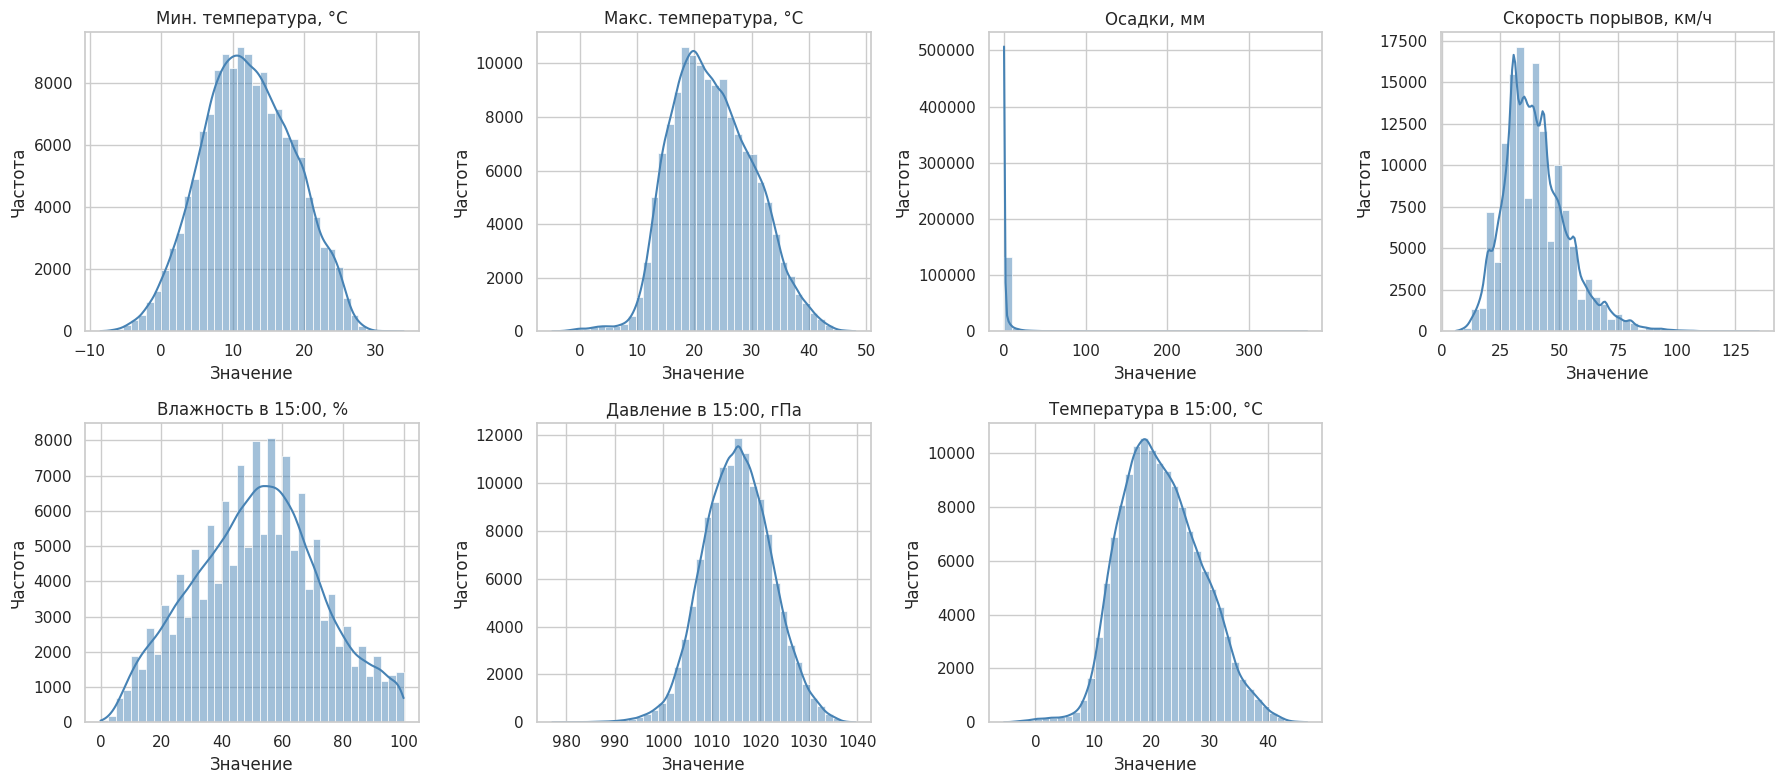

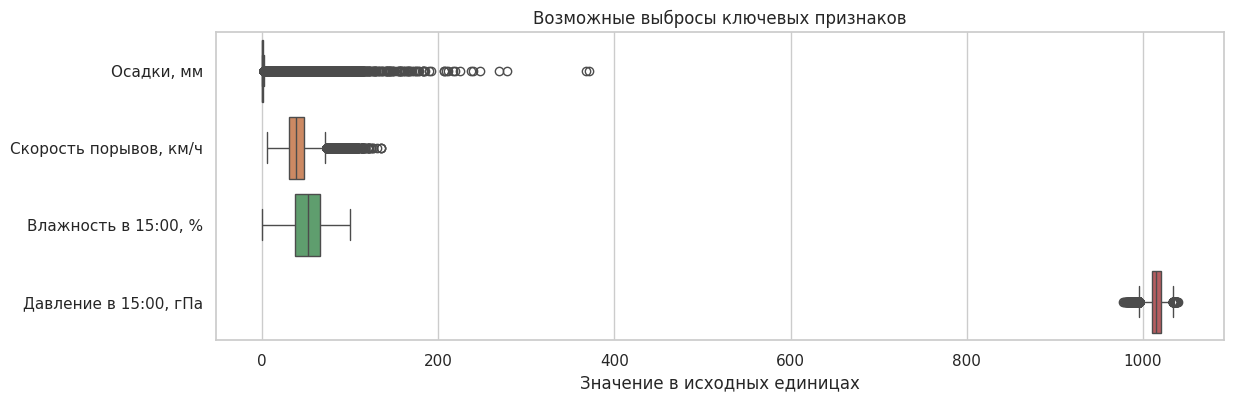

In [71]:
feature_labels = {
    'MinTemp': 'Мин. температура, °C', 'MaxTemp': 'Макс. температура, °C',
    'Rainfall': 'Осадки, мм', 'WindGustSpeed': 'Скорость порывов, км/ч',
    'Humidity3pm': 'Влажность в 15:00, %', 'Pressure3pm': 'Давление в 15:00, гПа',
    'Temp3pm': 'Температура в 15:00, °C'
}
hist_cols = list(feature_labels)
fig, axes = plt.subplots(2, 4, figsize=(18, 8))
for ax, col in zip(axes.ravel(), hist_cols):
    sns.histplot(df[col].dropna(), bins=40, kde=True, ax=ax, color='steelblue')
    ax.set_title(feature_labels[col])
    ax.set_xlabel('Значение')
    ax.set_ylabel('Частота')
for ax in axes.ravel()[len(hist_cols):]:
    ax.remove()
plt.tight_layout()
plt.show()

box_data = df[['Rainfall', 'WindGustSpeed', 'Humidity3pm', 'Pressure3pm']].rename(columns=feature_labels)
plt.figure(figsize=(13, 4))
sns.boxplot(data=box_data, orient='h')
plt.title('Возможные выбросы ключевых признаков')
plt.xlabel('Значение в исходных единицах')
plt.show()

Осадки и скорость порывов имеют правую асимметрию; температура и давление распределены более гладко. Диаграмма размаха выявляет экстремальные значения, но они сохраняются: сильный ветер и ливни являются реальными метеорологическими событиями. Разная шкала и форма распределений обосновывают стандартизацию числовых переменных перед обучением нейросети и кластеризацией.

## 2. Предобработка и выбор архитектуры

Из признаков исключаются дата, станция `Location` и целевая метка. Станция исключена намеренно: иначе кластеры преимущественно описывали бы географию, а не состояние погоды. Для воспроизводимости и приемлемого времени обучения используется стратифицированная выборка 5 000 наблюдений.

In [72]:
numeric_cols = ['MinTemp', 'MaxTemp', 'Rainfall', 'Evaporation', 'Sunshine',
                'WindGustSpeed', 'WindSpeed9am', 'WindSpeed3pm',
                'Humidity9am', 'Humidity3pm', 'Pressure9am', 'Pressure3pm',
                'Cloud9am', 'Cloud3pm', 'Temp9am', 'Temp3pm']
categorical_cols = ['WindGustDir', 'WindDir9am', 'WindDir3pm', 'RainToday']
model_cols = numeric_cols + categorical_cols

work = df[model_cols + ['RainTomorrow']].copy()
work = work[work['RainTomorrow'].isin(['Yes', 'No'])].copy()
work['RainTomorrow_binary'] = (work['RainTomorrow'] == 'Yes').astype(int)

n_sample = min(5000, len(work))
sample = (work.groupby('RainTomorrow_binary', group_keys=False)
          .apply(lambda x: x.sample(n=max(1, round(n_sample * len(x) / len(work))),
                                  random_state=RANDOM_STATE))
          .sample(frac=1, random_state=RANDOM_STATE).head(n_sample).reset_index(drop=True))
X_raw = sample[model_cols]
y_external = sample['RainTomorrow_binary'].to_numpy()

preprocessor = ColumnTransformer([
    ('num', Pipeline([('imputer', SimpleImputer(strategy='median')),
                      ('scaler', StandardScaler())]), numeric_cols),
    ('cat', Pipeline([('imputer', SimpleImputer(strategy='most_frequent')),
                      ('onehot', OneHotEncoder(handle_unknown='ignore', sparse_output=False))]), categorical_cols)
])
X = preprocessor.fit_transform(X_raw).astype('float32')
feature_names = preprocessor.get_feature_names_out()
display(pd.DataFrame({'Размерность до кодирования': [len(model_cols)],
                      'Размерность после кодирования': [X.shape[1]],
                      'Объектов для обучения': [len(X)] }))

,Размерность до кодирования,Размерность после кодирования,Объектов для обучения
0,20,66,5000


После кодирования получено 66 числовых признаков для 5 000 объектов. Медианное заполнение устойчиво к выбросам, а `StandardScaler` устраняет влияние исходных единиц измерения на расстояния. Целевая метка отсутствует во входе модели и будет использована только в метриках ARI и NMI.

### Обоснование автокодировщика

Выбран симметричный полносвязный автокодировщик `66 → 32 → z → 32 → 66`. Он подходит для табличных признаков после one-hot-кодирования. Энкодер сжимает наблюдение в латентный вектор `z`, декодер восстанавливает исходные признаки.

Используется функция потерь MSE (ошибка реконструкции) и L2-регуляризация весов. MSE уместна, поскольку после преобразования все входы числовые и числовые признаки стандартизированы. L2 ограничивает слишком большие веса и уменьшает риск переобучения. После обучения K-means ищет кластеры именно в латентном пространстве. Это вариант пайплайна **Autoencoder + K-means**, близкий по идее к первому этапу DEC; явная DEC-кластерная потеря не применяется, чтобы не использовать произвольные псевдометки.

In [73]:
def build_autoencoder(input_dim, latent_dim, learning_rate, l2_value):
    tf.keras.backend.clear_session()
    tf.keras.utils.set_random_seed(RANDOM_STATE)
    reg = regularizers.l2(l2_value)
    inputs = layers.Input(shape=(input_dim,), name='input_features')
    h = layers.Dense(32, activation='relu', kernel_regularizer=reg, name='encoder_dense_32')(inputs)
    z = layers.Dense(latent_dim, activation='linear', kernel_regularizer=reg, name='latent_layer')(h)
    h = layers.Dense(32, activation='relu', kernel_regularizer=reg, name='decoder_dense_32')(z)
    outputs = layers.Dense(input_dim, activation='linear', name='reconstruction')(h)
    autoencoder = Model(inputs, outputs, name='autoencoder')
    encoder = Model(inputs, z, name='encoder')
    autoencoder.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=learning_rate), loss='mse')
    return autoencoder, encoder

architecture = pd.DataFrame({
    'Часть модели': ['Вход', 'Энкодер', 'Латентный слой', 'Декодер', 'Выход'],
    'Размерность': [X.shape[1], 32, 'подбирается: 2 или 6', 32, X.shape[1]],
    'Активация': ['—', 'ReLU', 'Линейная', 'ReLU', 'Линейная']
})
display(architecture)

,Часть модели,Размерность,Активация
0,Вход,66,—
1,Энкодер,32,ReLU
2,Латентный слой,подбирается: 2 или 6,Линейная
3,Декодер,32,ReLU
4,Выход,66,Линейная


Скрытый слой из 32 нейронов даёт модели достаточную нелинейность без чрезмерного числа параметров. Латентные размерности 2 и 6 позволяют сравнить сильное сжатие с более ёмким представлением. Линейный выход не ограничивает восстановление стандартизированных значений, которые могут быть отрицательными.

## 3. Подбор гиперпараметров и обучение

Подбираются размерность латентного пространства, скорость обучения и L2-регуляризация. Для каждого варианта автокодировщик обучается 35 эпох с ранней остановкой; затем K-means подбирает число кластеров от 2 до 6 по максимальному силуэту в латентном пространстве.

In [74]:
search_grid = [
    {'latent_dim': 2, 'learning_rate': 1e-3, 'l2_value': 1e-5},
    {'latent_dim': 6, 'learning_rate': 1e-3, 'l2_value': 1e-5},
    {'latent_dim': 6, 'learning_rate': 5e-4, 'l2_value': 1e-5},
    {'latent_dim': 6, 'learning_rate': 1e-3, 'l2_value': 1e-4}
]
search_rows, trained_models = [], []

for cfg in search_grid:
    autoencoder, encoder = build_autoencoder(X.shape[1], **cfg)
    early_stop = tf.keras.callbacks.EarlyStopping(monitor='val_loss', patience=5,
                                                  restore_best_weights=True, verbose=0)
    history = autoencoder.fit(X, X, validation_split=0.2, epochs=35, batch_size=128,
                              callbacks=[early_stop], verbose=0, shuffle=True)
    Z = encoder.predict(X, verbose=0)
    scores = []
    for k in range(2, 7):
        labels = KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE).fit_predict(Z)
        scores.append(silhouette_score(Z, labels, sample_size=min(3000, len(Z)), random_state=RANDOM_STATE))
    best_idx = int(np.argmax(scores))
    search_rows.append({**cfg, 'Номер модели': len(trained_models),
                        'Эпох обучения': len(history.history['loss']),
                        'Лучшая val_loss': min(history.history['val_loss']),
                        'Лучшее k': best_idx + 2, 'Силуэт в латентном пространстве': scores[best_idx]})
    trained_models.append((autoencoder, encoder, history, Z, cfg))

search_results = pd.DataFrame(search_rows).sort_values(
    ['Силуэт в латентном пространстве', 'Лучшая val_loss'], ascending=[False, True]).reset_index(drop=True)
display(search_results.drop(columns='Номер модели').round(4))
best_cfg = search_results.iloc[0]
best_pos = int(best_cfg['Номер модели'])
best_autoencoder, best_encoder, best_history, Z, _ = trained_models[best_pos]
best_k = int(best_cfg['Лучшее k'])

,latent_dim,learning_rate,l2_value,Эпох обучения,Лучшая val_loss,Лучшее k,Силуэт в латентном пространстве
0,2,0.0010,0.0000,35,0.1567,2,0.3664
1,6,0.0010,0.0001,35,0.0835,2,0.2682
2,6,0.0010,0.0000,35,0.0808,2,0.2572
3,6,0.0005,0.0000,35,0.0885,2,0.2539


Лучшей оказалась конфигурация с латентной размерностью 2, скоростью обучения 0,001 и L2-регуляризацией `1e-5`: её силуэт в латентном пространстве равен 0,366, а `val_loss` — 0,157. Во всех четырёх конфигурациях оптимально `k=2`. Более ёмкое 6-мерное пространство снижает ошибку реконструкции до 0,081, но ухудшает силуэт до 0,254–0,268. Для задачи кластеризации выбран более компактный двухмерный латентный слой: он лучше разделяет группы, хотя восстанавливает вход несколько грубее.

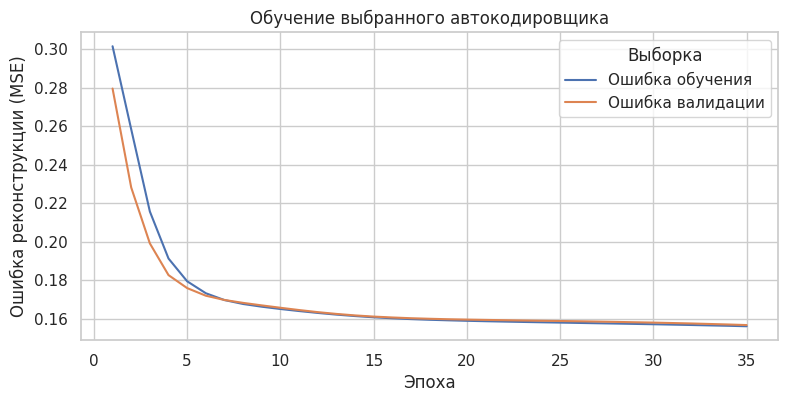

In [75]:
history_frame = pd.DataFrame({
    'Эпоха': np.arange(1, len(best_history.history['loss']) + 1),
    'Ошибка обучения': best_history.history['loss'],
    'Ошибка валидации': best_history.history['val_loss']
})
plt.figure(figsize=(9, 4))
sns.lineplot(data=history_frame.melt(id_vars='Эпоха', var_name='Выборка', value_name='MSE'),
             x='Эпоха', y='MSE', hue='Выборка')
plt.title('Обучение выбранного автокодировщика')
plt.xlabel('Эпоха')
plt.ylabel('Ошибка реконструкции (MSE)')
plt.show()

Выбранная модель прошла все 35 запланированных эпох: ранняя остановка не сработала. По графику ошибка обучения и валидации снижаются без резкого расхождения, поэтому в данном диапазоне эпох нет явного признака переобучения. Важнее, что качество реконструкции рассматривается вместе с силуэтом: минимальная MSE сама по себе не гарантирует наиболее удачного кластерного представления.

## 4. Глубокая кластеризация и сравнение с классическими методами

In [76]:
# Deep clustering: K-means в латентном пространстве выбранного энкодера
deep_kmeans = KMeans(n_clusters=best_k, n_init=20, random_state=RANDOM_STATE)
labels_deep = deep_kmeans.fit_predict(Z)

# Два классических базовых метода в исходном стандартизированном пространстве
classic_kmeans = KMeans(n_clusters=best_k, n_init=20, random_state=RANDOM_STATE)
labels_classic = classic_kmeans.fit_predict(X)
gmm = GaussianMixture(n_components=best_k, covariance_type='diag', n_init=3, random_state=RANDOM_STATE)
labels_gmm = gmm.fit_predict(X)

def evaluate_labels(name, labels):
    homogeneity, completeness, v_measure = homogeneity_completeness_v_measure(y_external, labels)
    return {
        'Метод': name,
        'Коэффициент силуэта ↑': silhouette_score(X, labels, sample_size=min(3000, len(X)), random_state=RANDOM_STATE),
        'Индекс Дэвиса—Боулдина ↓': davies_bouldin_score(X, labels),
        'Индекс Калински—Харабаша ↑': calinski_harabasz_score(X, labels),
        'Скорректированный индекс Рэнда ↑': adjusted_rand_score(y_external, labels),
        'Нормализованная взаимная информация ↑': normalized_mutual_info_score(y_external, labels),
        'V-мера ↑': v_measure
    }

comparison_metrics = pd.DataFrame([
    evaluate_labels('Автокодировщик + K-means', labels_deep),
    evaluate_labels('Классический K-means', labels_classic),
    evaluate_labels('Gaussian Mixture', labels_gmm)
]).set_index('Метод')
display(comparison_metrics.round(3))

,Коэффициент силуэта ↑,Индекс Дэвиса—Боулдина ↓,Индекс Калински—Харабаша ↑,Скорректированный индекс Рэнда ↑,Нормализованная взаимная информация ↑,V-мера ↑
Метод,,,,,,
Автокодировщик + K-means,0.142,2.155,945.406006,-0.002,0.046,0.046
Классический K-means,0.155,2.077,1038.995972,-0.004,0.016,0.016
Gaussian Mixture,0.024,5.925,118.833000,-0.016,0.005,0.005


В исходном 66-мерном пространстве классический K-means оказался лучше по внутреннему качеству: силуэт 0,155 против 0,142, индекс Дэвиса—Боулдина 2,077 против 2,155 и индекс Калински—Харабаша 1 039 против 945. Автокодировщик + K-means имеет немного более высокие внешние NMI и V-меру (0,046 против 0,016), но эти значения всё равно низкие; ARI обоих методов близок к нулю. Gaussian Mixture существенно уступает по всем внутренним метрикам. Следовательно, для данного набора глубокое сжатие формирует визуально более разделимое латентное пространство, но не улучшает итоговое разбиение в исходных данных относительно обычного K-means.

## 5. Визуализация латентного пространства и интерпретация

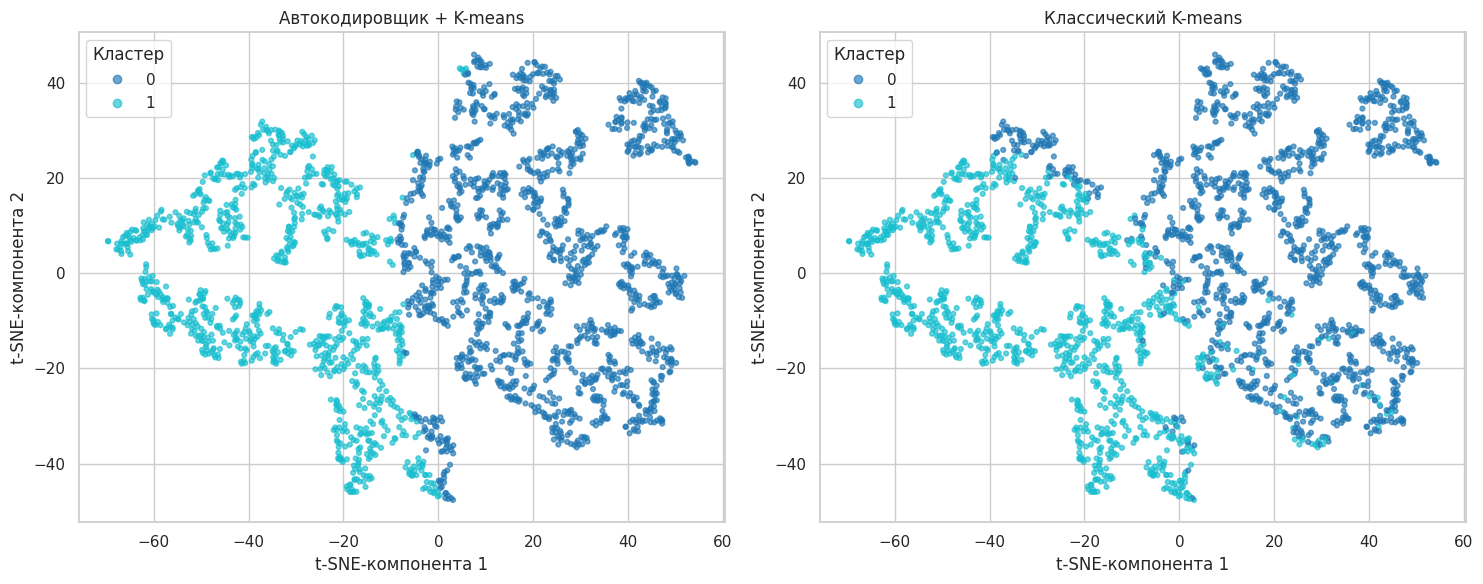

In [77]:
# t-SNE строится на подвыборке: это визуализация, а не пространство для метрик
viz_n = min(2500, len(Z))
rng = np.random.default_rng(RANDOM_STATE)
viz_idx = rng.choice(len(Z), size=viz_n, replace=False)
perplexity = min(30, max(5, (viz_n - 1) // 3))
Z_tsne = TSNE(n_components=2, perplexity=perplexity, learning_rate='auto',
              init='pca', random_state=RANDOM_STATE).fit_transform(Z[viz_idx])

fig, axes = plt.subplots(1, 2, figsize=(15, 6))
for ax, labels, title in zip(axes, [labels_deep[viz_idx], labels_classic[viz_idx]],
                            ['Автокодировщик + K-means', 'Классический K-means']):
    scatter = ax.scatter(Z_tsne[:, 0], Z_tsne[:, 1], c=labels, cmap='tab10', s=12, alpha=0.65)
    ax.set_title(title)
    ax.set_xlabel('t-SNE-компонента 1')
    ax.set_ylabel('t-SNE-компонента 2')
    ax.legend(*scatter.legend_elements(), title='Кластер')
plt.tight_layout()
plt.show()

На t-SNE-проекции латентного пространства видны два основных погодных режима и переходная область между ними. Такое изображение согласуется с тем, что латентный силуэт равен 0,366, однако оно не отменяет сравнения метрик в исходном пространстве: там классический K-means сохраняет преимущество. Поэтому t-SNE подтверждает наличие укрупнённой структуры, но не доказывает превосходство глубокого метода.

,"Мин. температура, °C","Макс. температура, °C","Осадки, мм",Sunshine,"Скорость порывов, км/ч","Влажность в 15:00, %","Давление в 15:00, гПа","Температура в 15:00, °C","Доля «дождь завтра», %"
Кластер,,,,,,,,,
0,9.75,18.99,3.73,5.52,39.49,60.32,1017.18,17.59,30.32
1,15.76,29.35,0.53,9.98,41.08,38.69,1012.87,27.65,11.09


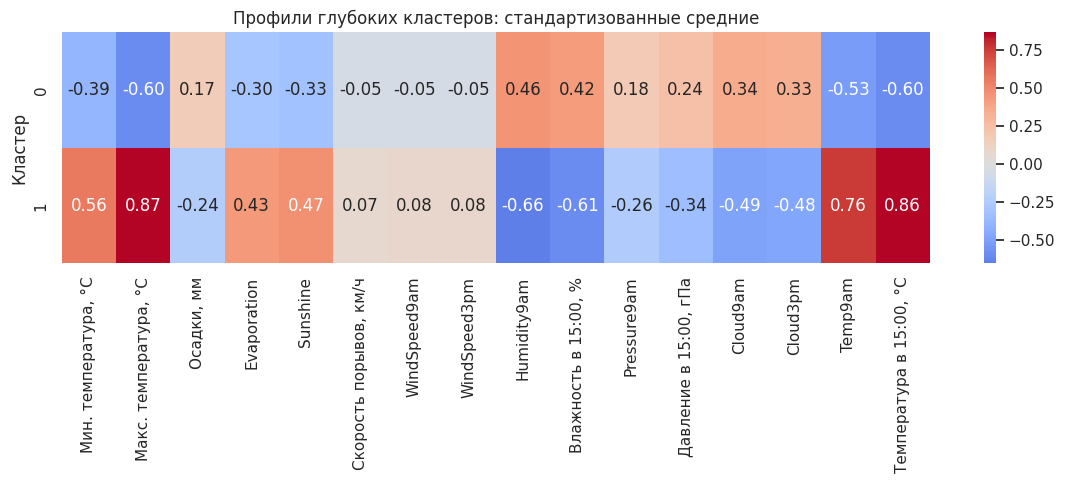

In [78]:
profile = sample[numeric_cols].copy()
profile['Кластер'] = labels_deep
profile['Дождь завтра, %'] = y_external * 100
profile_means = profile.groupby('Кластер').mean()
profile_show = profile_means[['MinTemp', 'MaxTemp', 'Rainfall', 'Sunshine', 'WindGustSpeed',
                              'Humidity3pm', 'Pressure3pm', 'Temp3pm', 'Дождь завтра, %']].rename(columns={
    **feature_labels, 'Дождь завтра, %': 'Доля «дождь завтра», %'
})
display(profile_show.round(2))

profile_z = pd.DataFrame(X[:, :len(numeric_cols)], columns=numeric_cols)
profile_z['Кластер'] = labels_deep
plt.figure(figsize=(14, max(3, best_k * 0.8)))
sns.heatmap(profile_z.groupby('Кластер').mean().rename(columns={c: feature_labels.get(c, c) for c in numeric_cols}),
            center=0, cmap='coolwarm', annot=True, fmt='.2f')
plt.title('Профили глубоких кластеров: стандартизованные средние')
plt.show()

Кластер 0 описывает прохладный и влажный режим: средняя температура в 15:00 равна 17,59 °C, влажность — 60,32 %, осадки — 3,73 мм, солнечное сияние — 5,52 часа. В кластере 1 наблюдается тёплый и сухой режим: 27,65 °C, 38,69 %, 0,53 мм и 9,98 часа соответственно. Доля дождя на следующий день выше в первом кластере — 30,32 % против 11,09 %. Это содержательно подтверждает выделение влажного и сухого типов погоды, хотя целевая метка при кластеризации не использовалась.

In [79]:
# Устойчивость: совпадение глубокого разбиения при другом начальном состоянии K-means
stability_rows = []
for seed in [7, 19, 101, 202]:
    repeated_labels = KMeans(n_clusters=best_k, n_init=20, random_state=seed).fit_predict(Z)
    stability_rows.append({'Начальное состояние': seed,
                           'ARI с исходным разбиением': adjusted_rand_score(labels_deep, repeated_labels)})
stability = pd.DataFrame(stability_rows)
display(stability.round(3))

,Начальное состояние,ARI с исходным разбиением
0,7,0.999
1,19,0.997
2,101,1.000
3,202,0.995


Разбиение устойчиво к смене инициализации K-means: ARI между исходным и повторными разбиениями находится в интервале 0,995–1,000. Следовательно, найденные два кластера не являются следствием одной случайной инициализации центров.

## 6. Заключение

В работе реализован пайплайн глубокой кластеризации «автокодировщик + K-means». Автокодировщик формирует сжатое нелинейное представление погодных признаков, а K-means группирует объекты в этом пространстве. Гиперпараметры выбираются без целевой метки по качеству реконструкции и силуэту.

Подбор выбрал двухмерное латентное пространство и два кластера; разбиение оказалось очень устойчивым к инициализации. Автокодировщик чётко разделил наблюдения в своём латентном пространстве, но при честной оценке в исходном пространстве уступил классическому K-means по всем внутренним метрикам. Поэтому для данного набора применение глубокой кластеризации полезно как способ визуализации и сжатого описания влажного и сухого погодных режимов, но не даёт практического преимущества над обычным K-means. Ни один из методов не заменяет классификатор дождя на следующий день.